In [5]:
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import fpgrowth, association_rules
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Chargement du dataset nettoyé
df = pd.read_csv("dataset_cleaned.csv")

print("=== 1. TRANSFORMATION EN FORMAT PANIER (BASKET MATRIX) ===")

# Agrégation par ticket au niveau RAYON
basket_rayon = (df.groupby(['ticket_id', 'rayon'])['quantite']
                .sum().unstack().reset_index().fillna(0)
                .set_index('ticket_id'))

# Binarisation : remplacement de applymap par map (Compatibilité Pandas 2.1+)
basket_encoded = basket_rayon.map(lambda x: 1 if x > 0 else 0)

print(f" Matrice Panier créée : {basket_encoded.shape[0]:,} tickets × {basket_encoded.shape[1]} rayons distincts.")
display(basket_encoded.head())

=== 1. TRANSFORMATION EN FORMAT PANIER (BASKET MATRIX) ===
 Matrice Panier créée : 32,225 tickets × 23 rayons distincts.


rayon,Beurres & Fromages,Boucherie,Boulangerie,Bébé,Café & Thé,Confiserie,Conserves,Crèmerie,Céréales & Confitures,Eaux & Jus,...,Huiles & Condiments,Hygiène & Soins,Légumes,Poissonnerie,Pâtisserie,Sauces & Soupes,Snacks,Sodas & Boissons,Surgelés,Épicerie Sèche
ticket_id,,,,,,,,,,,,,,,,,,,,,
T000001,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
T000002,0,0,0,0,0,0,0,1,0,0,...,0,1,0,0,0,0,0,0,0,0
T000003,0,0,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1
T000004,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
T000005,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [6]:
print("=== 2. EXTRACTION DES MOTIFS FRÉQUENTS AVEC FP-GROWTH ===")

# Support minimum défini à 2% (ajustable selon le niveau de granularité)
min_support = 0.02

frequent_itemsets = fpgrowth(basket_encoded, min_support=min_support, use_colnames=True)

# Tri par support décroissant
frequent_itemsets = frequent_itemsets.sort_values(by='support', ascending=False)

print(f" Nombre de motifs fréquents extraits (Support >= {min_support*100}%) : {len(frequent_itemsets)}")
display(frequent_itemsets.head(10))

=== 2. EXTRACTION DES MOTIFS FRÉQUENTS AVEC FP-GROWTH ===


/home/yves-mapendo/optimisation_rayon/optimisation_rayon/lib/python3.11/site-packages/mlxtend/frequent_patterns/fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


 Nombre de motifs fréquents extraits (Support >= 2.0%) : 61


,support,itemsets
3,0.363476,frozenset({Épicerie Sèche})
11,0.220078,frozenset({Sauces & Soupes})
10,0.211171,frozenset({Eaux & Jus})
5,0.205710,frozenset({Huiles & Condiments})
8,0.173592,frozenset({Boulangerie})
1,0.151870,frozenset({Crèmerie})
17,0.149915,frozenset({Conserves})
13,0.134833,frozenset({Entretien Ménager})
2,0.124375,frozenset({Hygiène & Soins})
4,0.104825,frozenset({Café & Thé})


In [7]:
print("=== 3. GENERATION ET FILTRAGE DES RÈGLES D'ASSOCIATION ===")

# Génération des règles d'association basées sur le Lift
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

# Nettoyage des formats frozenset pour l'affichage
rules["antecedents"] = rules["antecedents"].apply(lambda x: ', '.join(list(x)))
rules["consequents"] = rules["consequents"].apply(lambda x: ', '.join(list(x)))

# Tri par Lift décroissant
rules_sorted = rules.sort_values(by='lift', ascending=False)

print(f" Total de règles d'association découvertes : {len(rules_sorted)}")
print("\n--- TOP 10 DES RÈGLES À FORTE AFFINITÉ (LIFT MAX) ---")
display(rules_sorted[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10))

# Enregistrement des règles pour la phase de calcul du SIS
rules_sorted.to_csv("regles_association_rayons.csv", index=False)
print(" Fichier 'regles_association_rayons.csv' enregistré avec succès !")

=== 3. GENERATION ET FILTRAGE DES RÈGLES D'ASSOCIATION ===
 Total de règles d'association découvertes : 18

--- TOP 10 DES RÈGLES À FORTE AFFINITÉ (LIFT MAX) ---


,antecedents,consequents,support,confidence,lift
15,Huiles & Condiments,"Sauces & Soupes, Épicerie Sèche",0.020140,0.097903,1.180737
14,"Sauces & Soupes, Épicerie Sèche",Huiles & Condiments,0.020140,0.242889,1.180737
8,Eaux & Jus,Sodas & Boissons,0.022343,0.105805,1.166057
9,Sodas & Boissons,Eaux & Jus,0.022343,0.246238,1.166057
17,Épicerie Sèche,"Huiles & Condiments, Sauces & Soupes",0.020140,0.055409,1.159441
12,"Huiles & Condiments, Sauces & Soupes",Épicerie Sèche,0.020140,0.421429,1.159441
16,Sauces & Soupes,"Huiles & Condiments, Épicerie Sèche",0.020140,0.091512,1.122986
13,"Huiles & Condiments, Épicerie Sèche",Sauces & Soupes,0.020140,0.247144,1.122986
3,Épicerie Sèche,Huiles & Condiments,0.081490,0.224195,1.089862
2,Huiles & Condiments,Épicerie Sèche,0.081490,0.396138,1.089862


 Fichier 'regles_association_rayons.csv' enregistré avec succès !


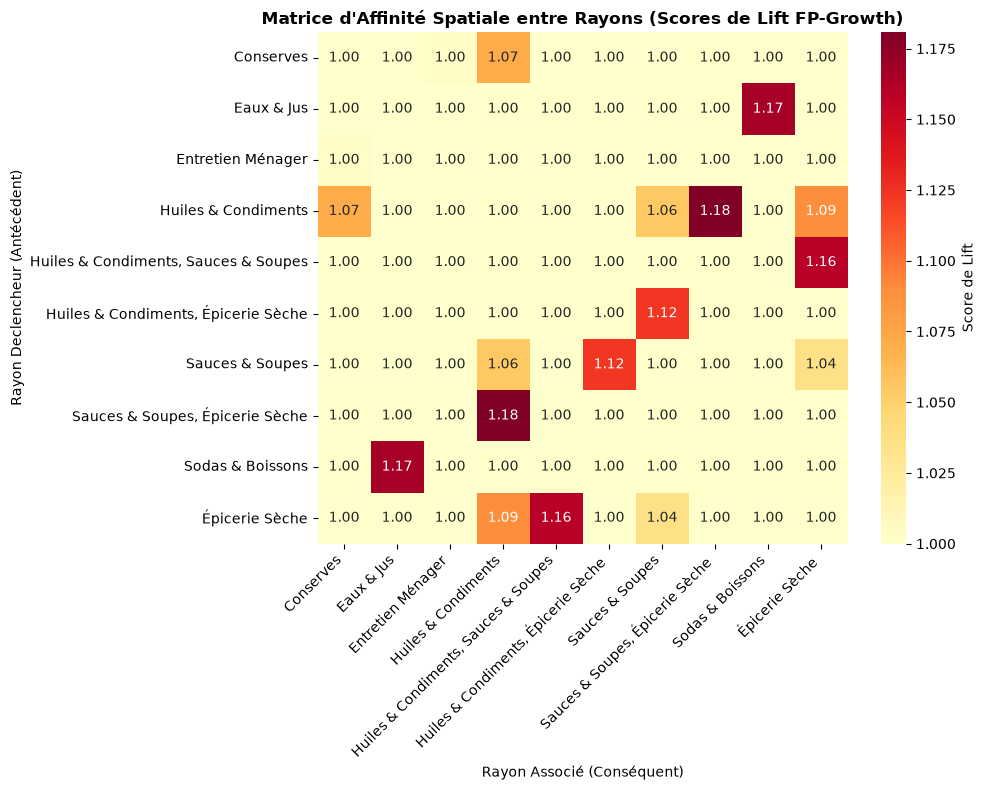

In [8]:
# Construction d'une matrice carrée des Lifts entre rayons
lift_matrix = rules.pivot(index='antecedents', columns='consequents', values='lift').fillna(1.0)

plt.figure(figsize=(10, 8))
sns.heatmap(lift_matrix, annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={'label': 'Score de Lift'})
plt.title("Matrice d'Affinité Spatiale entre Rayons (Scores de Lift FP-Growth)", fontsize=12, fontweight='bold')
plt.xlabel("Rayon Associé (Conséquent)", fontsize=10)
plt.ylabel("Rayon Declencheur (Antécédent)", fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()